# 结构生成：IR + Raman + NMR

从分子谱图生成结构。

openSpec 模型通过 Vib2Mol 编码谱通道。生成使用 beam search 和分子匹配分数；检索比较嵌入，候选重排使用匹配头。

本教程读取保存的预测，解释输入输出字段，并评估结果。最后给出在新数据集上运行模型的命令。

In [1]:
import json, sys, io
from pathlib import Path
from IPython.display import display, Markdown, SVG
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'openmolspec_bench').is_dir()), None)
if root is None:
    raise RuntimeError('Run from the cloned release repository; see Quick Start')
sys.path.insert(0, str(root / 'scripts'))
from documentation_evidence import load_evidence, compact, recompute, render
from documentation_content import results_table
evidence = load_evidence('vibrational.generation.hc')
print('Task:', evidence['task'])
print('Examples:', len(evidence['examples']))

Task: vibrational.generation.hc
Examples: 3


## 输入与输出

| Field | Meaning |
| --- | --- |
| `IR / Raman` | 每个可见通道 1024 个强度点，按 400→4000 cm⁻¹ 排列，并采用 checkpoint 的归一化。 |
| `1H / 13C` | 逐原子位移数组（ppm），参考 ID 和归一化必须与 checkpoint 一致。 |

| Field | Meaning |
| --- | --- |
| `SMILES candidates` | 解码后有效、规范化且去重的结构；完整输入路径使用 beam 10 和 ITM 重排。 |
| `top-k` | 分别报告生成与重排后的 top-k；不提供分子式。 |

查看下面的示例记录。长数组显示长度与前几个数值，下载 JSON 可获取完整数组。

In [2]:
for example in evidence['examples'][:3]:
    print(json.dumps(compact(example), indent=2, ensure_ascii=False))

{
  "target": "CC(C)OCC1=NC(C2CCC2)=CS1",
  "raw_beams": {
    "length": 10,
    "first_values": [
      "CC(C)OCC1=NC(C2CCC2)=CS1",
      "CC(OCC1=NC(=CS1)C1CCC1)C",
      "CC(OCC1=NC(C2CCC2)=CS1)C",
      "CC(OCC1SC=C(N=1)C1CCC1)C",
      "CC(OCC1SC=C(C2CCC2)N=1)C",
      "C1CCC1C1=CSC(=N1)COC(C)C",
      "C1CCC1C1=CSC(COC(C)C)=N1",
      "C1(CCC1)C1=CSC(=N1)COC(C)C"
    ]
  },
  "unique_candidates": [
    "CC(C)OCC1=NC(C2CCC2)=CS1"
  ],
  "reranked": [
    "CC(C)OCC1=NC(C2CCC2)=CS1"
  ],
  "positive_probabilities": [
    0.9998494386672974
  ],
  "input": {
    "ir": {
      "length": 1024,
      "first_values": [
        0.005309805274009705,
        0.005845691077411175,
        0.006656948011368513,
        0.007852676324546337,
        0.009617962874472141,
        0.012248368002474308,
        0.016140293329954147,
        0.02150154486298561
      ]
    },
    "raman": {
      "length": 1024,
      "first_values": [
        0.004348924849182367,
        0.0044013503938913345,


## 评估预测

生成报告 top-k 准确率，排序报告 Recall@k 与 MRR。

表格给出每次运行的数据集与指标。后续代码从绘图使用的预测值重新计算汇总结果。

In [3]:
display(Markdown(results_table(evidence, False)))
print(json.dumps(recompute(evidence), indent=2, ensure_ascii=False))

| Dataset / scope | Model / variant | Metric | Value |
| --- | --- | --- | ---: |
| recorded sample | recorded model | exact_canonical_top1 | 0.75 |
| recorded sample | recorded model | exact_canonical_top3 | 0.890625 |
| recorded sample | recorded model | exact_canonical_top5 | 0.890625 |
| recorded sample | recorded model | exact_canonical_top10 | 0.890625 |
| recorded sample | recorded model | valid_smiles_fraction | 0.959375 |
| recorded sample | recorded model | duplicate_valid_beams | 455 |
| recorded sample | recorded model | examples | 64 |
| recorded sample | ITM reranked | exact_canonical_top1 | 0.6875 |
| recorded sample | ITM reranked | exact_canonical_top3 | 0.84375 |
| recorded sample | ITM reranked | exact_canonical_top5 | 0.890625 |
| recorded sample | ITM reranked | exact_canonical_top10 | 0.890625 |


{
  "top1_matches_reference_this_example": true
}


## 查看结果图

参考结构与生成候选。

比较预测与参考，查看返回的结构或峰位置。图由上方读取的记录直接生成。

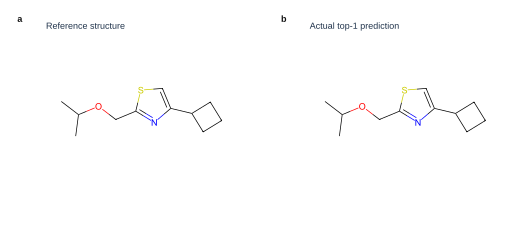

In [4]:
import matplotlib.pyplot as plt
for example_index in range(1):
    figure = render('vibrational.generation.hc', evidence, example_index=example_index)
    image = io.StringIO()
    figure.savefig(image, format='svg', metadata={'Date': None})
    display(SVG(image.getvalue()))
    plt.close(figure)

## 运行模型

按任务指南配置环境和权重，在 benchmark runner 中选择本任务，即可评估自己的数据集。

```bash
python -m openmolspec_bench run --workspace /path/to/OpenMolSpec \
  --tasks vibrational.generation.hc --limit 8 --output results/vibrational-generation-hc.json
```

[Task](../tasks/vibrational-generation-hc.md) · [Quick start](../quickstart.md)



## 参考文献

- OpenMolSpec contributors. openSpec models and benchmark training workflows. Source archive, v1.0 (2026). [Source](https://github.com/jiaqingxie/openmolspec-studio-frontend/tree/release/openmolspec-v1/documentation/assets/benchmarks)
- OpenMolSpec contributors. OpenMolSpec: Chemical spectroscopy datasets, models and learning workflows. Software release v1.0 (2026). [Source](https://github.com/jiaqingxie/openmolspec-studio-frontend/releases/tag/v1.0)
- Yuan, M., Zou, Z. & Hu, W. QMe14S, A Comprehensive and Efficient Spectral Dataset for Small Organic Molecules. arXiv:2501.18876 (2025). [Source](https://arxiv.org/abs/2501.18876)
- Zou, Z., Zhang, Y., Liang, L., Wei, M., Leng, J., Jiang, J., Luo, Y. & Hu, W. A deep learning model for predicting selected organic molecular spectra. Nature Computational Science 3, 957–964 (2023). doi:10.1038/s43588-023-00550-y. [Source](https://www.nature.com/articles/s43588-023-00550-y)
